# Smart Energy Load Forecaster and Anomaly Detector
Predicts household electricity usage for the next 1–3 days and flags unusual readings.
Data: UCI Household Electric Power Consumption (one house, one reading per minute, Dec 2006 – Nov 2010).

# Step 1: Get and understand the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1.1 Load the data with pandas

In [2]:
df = pd.read_csv("data/household_power_consumption.txt", sep=";", na_values=["?"], low_memory=False)
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
df["timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
df = df.set_index("timestamp").drop(columns=["Date", "Time"])
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
timestamp,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [4]:
print(df.shape)
print(df.index.min(), "to", df.index.max())
df.info()

(2075259, 7)
2006-12-16 17:24:00 to 2010-11-26 21:02:00
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


## 1.2 Look for patterns (by hour, day of week, month)

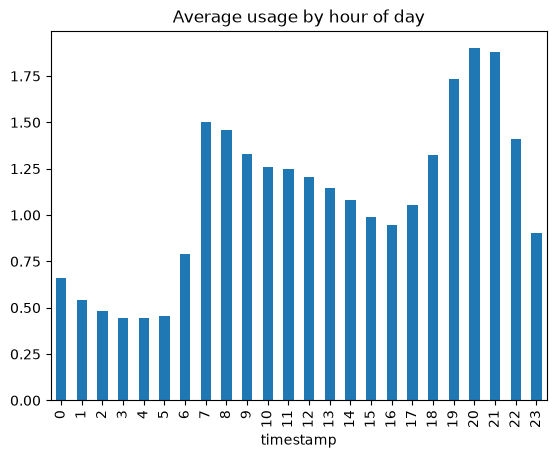

In [5]:
df.groupby(df.index.hour)["Global_active_power"].mean().plot(kind="bar", title="Average usage by hour of day")
plt.show()

C:\Users\abdullah.zafar\AppData\Local\Temp\ipykernel_21908\671758121.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df.groupby(df.index.dayofweek)["Global_active_power"].mean().plot(kind="bar", title="Average usage by day (0=Monday, 6=Sunday)")


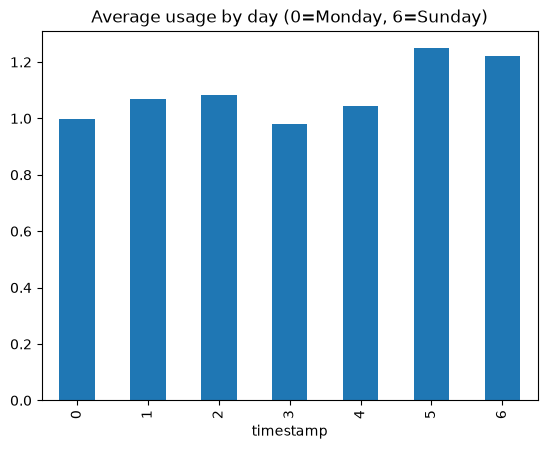

In [6]:
df.groupby(df.index.dayofweek)["Global_active_power"].mean().plot(kind="bar", title="Average usage by day (0=Monday, 6=Sunday)")
plt.show()

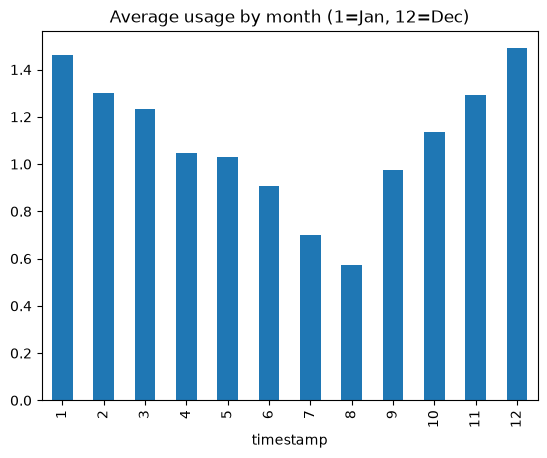

In [7]:
df.groupby(df.index.month)["Global_active_power"].mean().plot(kind="bar", title="Average usage by month (1=Jan, 12=Dec)")
plt.show()

Highest at 20:00	People are home from work: cooking, lights, TV, washing. Lowest is around 3–5am, when everyone is asleep.
Highest on Saturday	People are home all day at weekends, so appliances run during daytime hours too. Weekends are higher than weekdays.
Highest in December	Winter in France means heating and long dark evenings with lights on. Summer is lowest, and August especially, because French families often go on holiday.

## 1.3 Clean the missing values

In [8]:
missing = df["Global_active_power"].isna()
print("Missing readings:", missing.sum())
print("Percent missing:", round(missing.mean() * 100, 2), "%")

Missing readings: 25979
Percent missing: 1.25 %


In [9]:
missing_per_day = missing.resample("D").sum()
print(missing_per_day.sort_values(ascending=False).head(10))

timestamp
2010-08-21    1440
2010-08-20    1440
2010-08-18    1440
2007-04-29    1440
2010-08-19    1440
2010-01-13    1440
2009-06-14    1440
2010-09-26    1440
2010-09-27    1440
2007-04-28    1419
Name: Global_active_power, dtype: int64


## 1.4 Convert minute readings to hourly

In [12]:
hourly = df["Global_active_power"].resample("h").mean()
print(len(hourly), "hours")
print("Missing hours:", hourly.isna().sum())

34589 hours
Missing hours: 421


In [13]:
hourly = hourly.interpolate(limit=3)      # Option B: short gaps (up to 3 hours) get a straight line
for i in range(4):
    hourly = hourly.fillna(hourly.shift(168))   # Option C: long gaps get the value from 168 hours (1 week) earlier
print("Missing hours after cleaning:", hourly.isna().sum())

Missing hours after cleaning: 0


1.25% of readings were missing, mostly as whole days. I averaged to hourly first. Short gaps (≤ 3 h) were filled by interpolation. Long gaps were filled with the same hour from the previous week, to keep the realistic daily pattern instead of a flat line

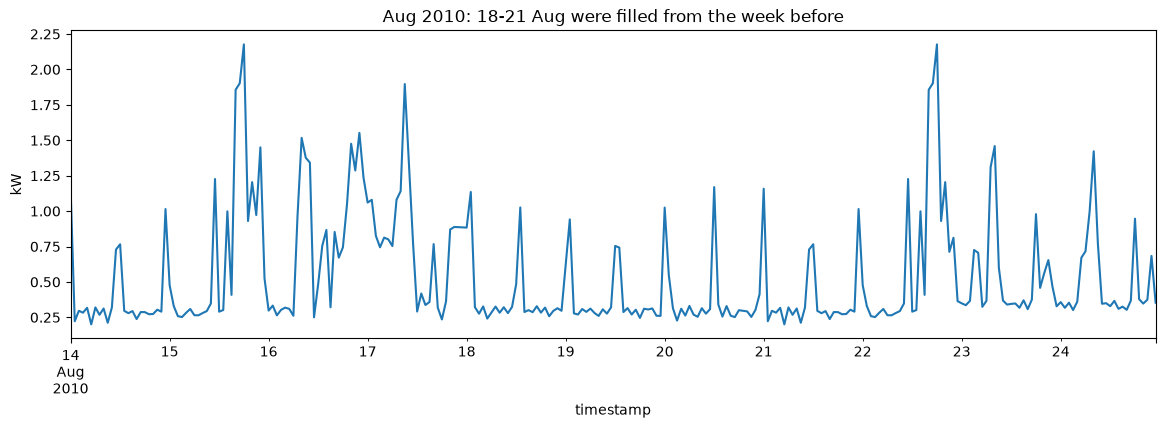

In [14]:
hourly.loc["2010-08-14":"2010-08-24"].plot(figsize=(14, 4), title="Aug 2010: 18-21 Aug were filled from the week before")
plt.ylabel("kW")
plt.show()

In [15]:
hourly.to_csv("data/hourly.csv")

# Step 2: Store the data in a database

## 2.1 Create a PostgreSQL database

In [7]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"), pool_pre_ping=True)

with engine.connect() as conn:
    print(conn.execute(text("SELECT version()")).scalar())

PostgreSQL 17.12 (4d8000a) on aarch64-unknown-linux-gnu, compiled by gcc (Debian 12.2.0-14+deb12u1) 12.2.0, 64-bit


## 2.2 Design a table for the readings

## 2.3 Load the cleaned data into the database

In [3]:
import pandas as pd

table = pd.read_csv("data/hourly.csv", parse_dates=["timestamp"])
table.columns = ["timestamp", "usage_kw"]
print(len(table), "rows")
table.head()

34589 rows


,timestamp,usage_kw
0,2006-12-16 17:00:00,4.222889
1,2006-12-16 18:00:00,3.632200
2,2006-12-16 19:00:00,3.400233
3,2006-12-16 20:00:00,3.268567
4,2006-12-16 21:00:00,3.056467


In [4]:
table.to_sql("readings", engine, if_exists="append", index=False, chunksize=5000)

-7

In [5]:
pd.read_sql("SELECT COUNT(*), MIN(timestamp), MAX(timestamp) FROM readings", engine)

,count,min,max
0,34589,2006-12-16 17:00:00,2010-11-26 21:00:00


# Step 3: Build a simple baseline first

In [8]:
data = pd.read_sql("SELECT timestamp, usage_kw FROM readings ORDER BY timestamp", engine, index_col="timestamp")
usage = data["usage_kw"]
print(len(usage), "hours")

34589 hours


In [9]:
test_start = usage.index.max() - pd.Timedelta(days=28)
test = usage[usage.index > test_start]
print(len(test), "hours in the test period, from", test.index.min(), "to", test.index.max())

672 hours in the test period, from 2010-10-29 22:00:00 to 2010-11-26 21:00:00


In [10]:
baseline = usage.shift(24)
baseline = baseline[baseline.index > test_start]

In [11]:
error = test - baseline
mae = error.abs().mean()
mape = (error.abs() / test).mean() * 100
print(f"Baseline MAE:  {mae:.3f} kW")
print(f"Baseline MAPE: {mape:.1f} %")

Baseline MAE:  0.617 kW
Baseline MAPE: 73.2 %


# Step 4: Train a forecasting model

In [1]:
# Setup: everything Step 4 needs
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

# connect to the database
load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"), pool_pre_ping=True)

# load the hourly data from the database (Step 3, Part 1)
data = pd.read_sql("SELECT timestamp, usage_kw FROM readings ORDER BY timestamp", engine, index_col="timestamp")
usage = data["usage_kw"]

# the start of the 4-week test period (Step 3, Part 2)
test_start = usage.index.max() - pd.Timedelta(days=28)

print(len(usage), "hours loaded, test period starts after", test_start)

34589 hours loaded, test period starts after 2010-10-29 21:00:00


## 4.1 Create features (lag, rolling, calendar)

In [2]:
features = pd.DataFrame(index=usage.index)

# Lag features: usage some time ago
features["lag_1"] = usage.shift(1)        # 1 hour ago
features["lag_24"] = usage.shift(24)      # 24 hours ago (same hour yesterday)
features["lag_168"] = usage.shift(168)    # 168 hours ago (same hour last week)

# Rolling features: average of recent hours
features["roll_mean_6"] = usage.shift(1).rolling(6).mean()     # average of the last 6 hours
features["roll_mean_24"] = usage.shift(1).rolling(24).mean()   # average of the last 24 hours

# Calendar features: what kind of time it is
features["hour"] = usage.index.hour
features["dayofweek"] = usage.index.dayofweek
features["month"] = usage.index.month
features["is_weekend"] = (usage.index.dayofweek >= 5).astype(int)

# The answer we want the model to learn to predict
features["target"] = usage

features = features.dropna()
features.head()

C:\Users\abdullah.zafar\AppData\Local\Temp\ipykernel_19440\3006036583.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  features["dayofweek"] = usage.index.dayofweek
C:\Users\abdullah.zafar\AppData\Local\Temp\ipykernel_19440\3006036583.py:16: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  features["is_weekend"] = (usage.index.dayofweek >= 5).astype(int)


,lag_1,lag_24,lag_168,roll_mean_6,roll_mean_24,hour,dayofweek,month,is_weekend,target
timestamp,,,,,,,,,,
2006-12-23 17:00:00,4.349100,1.496800,4.222889,3.608378,2.934890,17,5,12,1,5.452533
2006-12-23 18:00:00,5.452533,2.686967,3.632200,3.990633,3.099713,18,5,12,1,3.879400
2006-12-23 19:00:00,3.879400,3.938167,3.400233,4.149067,3.149397,19,5,12,1,4.117833
2006-12-23 20:00:00,4.117833,3.536067,3.268567,4.267656,3.156883,20,5,12,1,4.181400
2006-12-23 21:00:00,4.181400,4.548667,3.056467,4.338228,3.183772,21,5,12,1,3.288433


## 4.2 Split by time, not randomly

In [3]:
train = features[features.index <= test_start]
test = features[features.index > test_start]

X_train = train.drop(columns="target")
y_train = train["target"]
X_test = test.drop(columns="target")
y_test = test["target"]

print(len(X_train), "training hours,", len(X_test), "test hours")

33749 training hours, 672 test hours


## 4.3 Train the LightGBM model

In [4]:
from lightgbm import LGBMRegressor

model = LGBMRegressor(n_estimators=500, learning_rate=0.03, verbose=-1)
model.fit(X_train, y_train)

,learning_rate,0.03
,n_estimators,500
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


## 4.4 Measure MAE and MAPE against the baselines

In [5]:
pred = model.predict(X_test)

model_mae = (y_test - pred).abs().mean()
model_mape = ((y_test - pred).abs() / y_test).mean() * 100

naive_1h = usage.shift(1)[usage.index > test_start]
naive_mae = (y_test - naive_1h).abs().mean()

print(f"Baseline (same hour yesterday): MAE = 0.617 kW")
print(f"Baseline (same as 1 hour ago):  MAE = {naive_mae:.3f} kW")
print(f"LightGBM model:                 MAE = {model_mae:.3f} kW, MAPE = {model_mape:.1f} %")

Baseline (same hour yesterday): MAE = 0.617 kW
Baseline (same as 1 hour ago):  MAE = 0.464 kW
LightGBM model:                 MAE = 0.368 kW, MAPE = 40.9 %


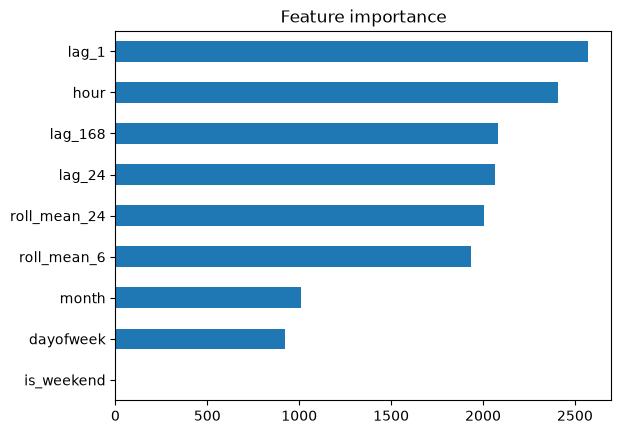

In [6]:
pd.Series(model.feature_importances_, index=X_train.columns).sort_values().plot(kind="barh", title="Feature importance")
plt.show()

## 4.5 Save the trained model

In [7]:
import joblib
joblib.dump(model, "model.joblib")

['model.joblib']

# Step 5: Detect unusual usage

## 5.1 Isolation Forest

In [8]:
from sklearn.ensemble import IsolationForest

iso_input = features[["target", "hour", "dayofweek"]]

iso = IsolationForest(contamination=0.01, random_state=42)
iso.fit(iso_input)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [9]:
iso_result = iso_input.copy()
iso_result["flag"] = iso.predict(iso_input)

iso_anomalies = iso_result[iso_result["flag"] == -1]
print("Hours flagged:", len(iso_anomalies))

Hours flagged: 345


In [10]:
iso_anomalies.sort_values("target", ascending=False).head(10)

,target,hour,dayofweek,flag
timestamp,,,,
2008-11-23 18:00:00,6.560534,18,6,-1
2009-01-16 20:00:00,6.519633,20,4,-1
2008-02-02 19:00:00,6.496033,19,5,-1
2007-12-23 19:00:00,6.488000,19,6,-1
2007-02-22 21:00:00,6.363867,21,3,-1
2007-12-28 17:00:00,6.333667,17,4,-1
2008-11-23 20:00:00,6.310567,20,6,-1
2007-01-21 20:00:00,6.076567,20,6,-1
2008-01-26 19:00:00,6.013800,19,5,-1


In [11]:
iso_anomalies.sort_values("target").head(10)

,target,hour,dayofweek,flag
timestamp,,,,
2007-08-13 00:00:00,1.982433,0,0,-1
2008-10-06 00:00:00,2.175700,0,0,-1
2007-08-28 00:00:00,2.255100,0,1,-1
2008-10-06 01:00:00,2.257133,1,0,-1
2007-04-01 00:00:00,2.324500,0,6,-1
2007-02-11 00:00:00,2.324667,0,6,-1
2007-03-25 00:00:00,2.376533,0,6,-1
2009-01-02 00:00:00,2.400700,0,4,-1
2006-12-26 00:00:00,2.424267,0,1,-1


## 5.2 Forecast-error method


In [12]:
X_all = features.drop(columns="target")

fc_result = features[["target", "hour", "dayofweek"]].copy()
fc_result["predicted"] = model.predict(X_all)
fc_result["error"] = fc_result["target"] - fc_result["predicted"]
fc_result["abs_error"] = fc_result["error"].abs()

In [13]:
threshold = fc_result["abs_error"].quantile(0.99)
fc_anomalies = fc_result[fc_result["abs_error"] > threshold]

print("Threshold (kW):", round(threshold, 3))
print("Hours flagged:", len(fc_anomalies))

Threshold (kW): 1.672
Hours flagged: 345


In [14]:
fc_anomalies.sort_values("error", ascending=False).head(10)

,target,hour,dayofweek,predicted,error,abs_error
timestamp,,,,,,
2010-02-21 11:00:00,5.090800,11,6,1.582803,3.507997,3.507997
2010-11-20 18:00:00,5.626833,18,5,2.155456,3.471378,3.471378
2009-02-11 18:00:00,5.233800,18,2,1.768397,3.465403,3.465403
2007-02-22 21:00:00,6.363867,21,3,3.294819,3.069048,3.069048
2007-03-31 10:00:00,5.161066,10,5,2.105926,3.055140,3.055140
2008-03-07 11:00:00,4.509733,11,4,1.476119,3.033614,3.033614
2009-10-23 15:00:00,4.025300,15,4,1.006673,3.018627,3.018627
2007-04-01 17:00:00,3.860100,17,6,0.842628,3.017472,3.017472
2007-05-08 12:00:00,4.719133,12,1,1.702649,3.016484,3.016484


In [15]:
fc_anomalies.sort_values("error").head(10)

,target,hour,dayofweek,predicted,error,abs_error
timestamp,,,,,,
2010-03-27 19:00:00,1.254633,19,5,3.364295,-2.109662,2.109662
2008-01-30 20:00:00,0.457200,20,2,2.530036,-2.072836,2.072836
2010-11-11 07:00:00,0.645933,7,3,2.614002,-1.968068,1.968068
2010-03-31 14:00:00,0.491533,14,2,2.415726,-1.924193,1.924193
2008-10-19 02:00:00,1.196033,2,6,3.095481,-1.899448,1.899448
2007-03-22 20:00:00,0.382133,20,3,2.206606,-1.824473,1.824473
2010-10-28 20:00:00,0.531900,20,3,2.344461,-1.812561,1.812561
2007-02-11 16:00:00,0.438500,16,6,2.216986,-1.778486,1.778486
2007-05-06 10:00:00,0.377667,10,6,2.136777,-1.759111,1.759111


## 5.3 Check flagged points by hand

In [16]:
both = iso_anomalies.index.intersection(fc_anomalies.index)
print("Flagged by both methods:", len(both))

Flagged by both methods: 128


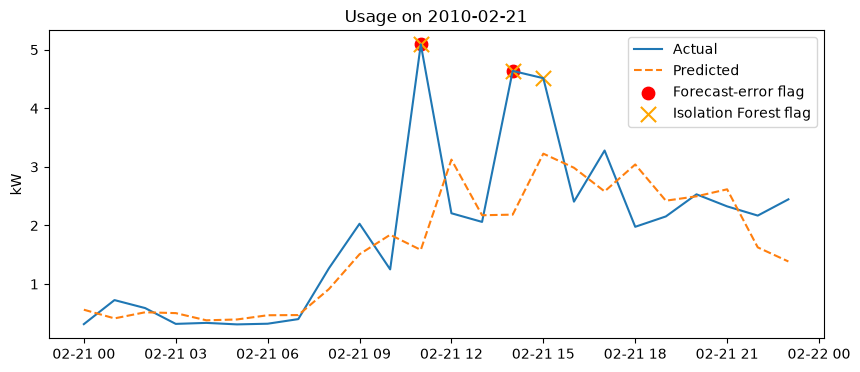

In [17]:
import matplotlib.pyplot as plt

day = "2010-02-21"

window = fc_result.loc[day]
fc_flags = window[window["abs_error"] > threshold]
iso_flags = window[window.index.isin(iso_anomalies.index)]

plt.figure(figsize=(10, 4))
plt.plot(window.index, window["target"], label="Actual")
plt.plot(window.index, window["predicted"], linestyle="--", label="Predicted")
plt.scatter(fc_flags.index, fc_flags["target"], color="red", s=80, label="Forecast-error flag")
plt.scatter(iso_flags.index, iso_flags["target"], color="orange", marker="x", s=120, label="Isolation Forest flag")
plt.title("Usage on " + day)
plt.ylabel("kW")
plt.legend()
plt.show()

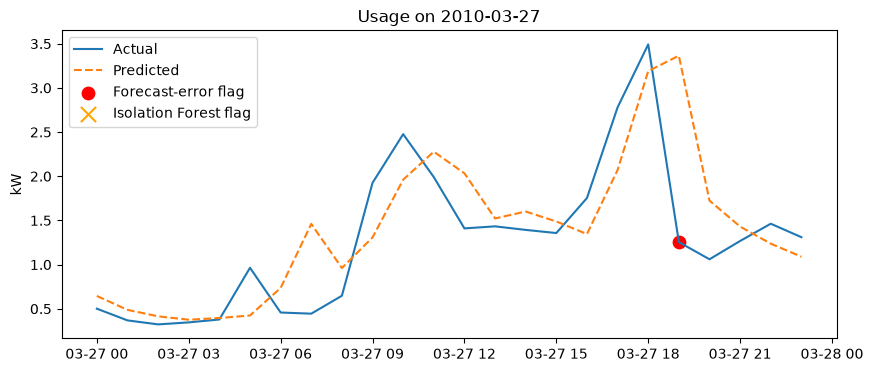

In [18]:
import matplotlib.pyplot as plt

day = "2010-03-27"

window = fc_result.loc[day]
fc_flags = window[window["abs_error"] > threshold]
iso_flags = window[window.index.isin(iso_anomalies.index)]

plt.figure(figsize=(10, 4))
plt.plot(window.index, window["target"], label="Actual")
plt.plot(window.index, window["predicted"], linestyle="--", label="Predicted")
plt.scatter(fc_flags.index, fc_flags["target"], color="red", s=80, label="Forecast-error flag")
plt.scatter(iso_flags.index, iso_flags["target"], color="orange", marker="x", s=120, label="Isolation Forest flag")
plt.title("Usage on " + day)
plt.ylabel("kW")
plt.legend()
plt.show()

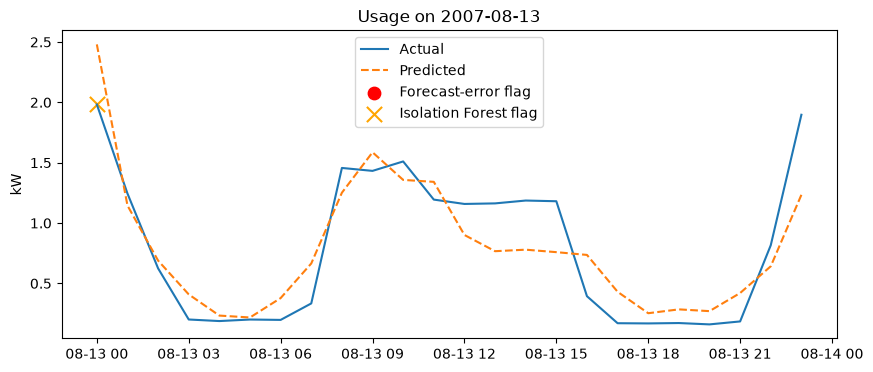

In [19]:
import matplotlib.pyplot as plt

day = "2007-08-13"

window = fc_result.loc[day]
fc_flags = window[window["abs_error"] > threshold]
iso_flags = window[window.index.isin(iso_anomalies.index)]

plt.figure(figsize=(10, 4))
plt.plot(window.index, window["target"], label="Actual")
plt.plot(window.index, window["predicted"], linestyle="--", label="Predicted")
plt.scatter(fc_flags.index, fc_flags["target"], color="red", s=80, label="Forecast-error flag")
plt.scatter(iso_flags.index, iso_flags["target"], color="orange", marker="x", s=120, label="Isolation Forest flag")
plt.title("Usage on " + day)
plt.ylabel("kW")
plt.legend()
plt.show()

## 5.4 Which method worked better and why

Conclusion: the forecast-error method worked better. It judges each reading against what is normal for that exact hour, day and recent history, so it finds both unexpected spikes and unexpected drops. Isolation Forest only flags readings that are extreme overall, and it produces false alarms at the edges of the hour and day ranges.